In [1]:
from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy 

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator
from src.selflensing.models import SelfLensingSystem

from src.selflensing.gp import TESSGP

In [2]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x11a655fd0>

In [3]:
LENSING_METHOD = 'IntegratedWittMao'

In [4]:
sls = SelfLensingSystem(
    a=2 * units.AU,
    i=0.4*numpy.pi * units.rad,
    Macc=30*units.M_sun,
    Mcomp=1*units.M_sun,
    Rcomp=1*units.R_sun,
    e=0 * units.dimensionless_unscaled,
    d=438.1*units.kpc,
)
sls.porb, sls.tau_eff, sls.b, sls.b_max, sls.rE(), sls.i, sls.tau_eff

/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:659: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


(<Quantity 185.55068993 d>,
 <Quantity nan d>,
 <Quantity 411.74768688>,
 <Quantity 4.09824245>,
 <Quantity 0.32276364 solRad>,
 <Quantity 1.25663706 rad>,
 <Quantity nan d>)

In [5]:
start_time = Time("2025-01-01")
end_time = Time("2025-01-28")
peak_time = Time("2025-01-14")

In [ ]:
lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, baseline=TESSGP, bins=27*24*6)
lcg_pure = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, baseline=numpy.median(lcg.flux_array),  bins=27*24*6)
rvg = RVGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time)

theta= [-3.0329204  -4.759645   -2.5100417   5.         -4.3476906  -0.84769046]


/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:659: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


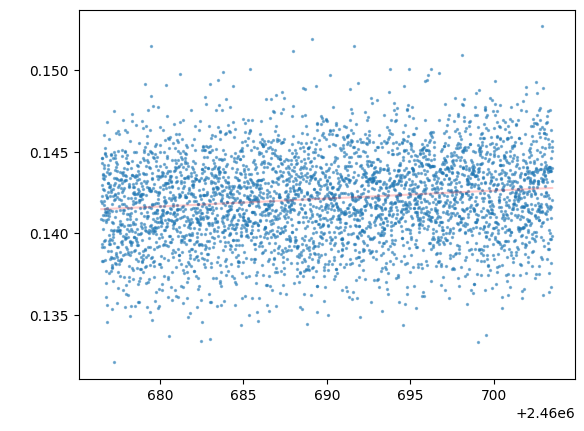

In [7]:
pyplot.plot(lcg_pure.times.jd, lcg_pure.flux_array, c='red', alpha=0.2)
pyplot.scatter(lcg.times.jd, lcg.flux_array, s=2, alpha=0.5)
pyplot.axvline(peak_time.jd - 5 * sls.tau_eff.value, alpha=0.2, color='red')
pyplot.axvline(peak_time.jd + 5 * sls.tau_eff.value, alpha=0.2, color='red')

In [8]:
tgp = TESSGP(sls, lcg.time_offsets, lcg.flux_array)
tgp.p0.shape

(5, 11)

In [9]:
gp_theta, sampler = tgp.fit()
gp_theta

100%|██████████| 2000/2000 [01:42<00:00, 19.55it/s]


array([-3.74124909e+00, -3.90241270e+00, -6.06503667e+00,  1.15127345e+01,
       -7.66382877e-01,  9.50027059e-01,  4.87649891e+00,  6.26176357e+00,
        1.48572460e+00,  3.46048950e+00,  5.79308695e-05])

In [10]:
max(sampler.get_log_prob(flat=True))

np.float64(17383.765625)

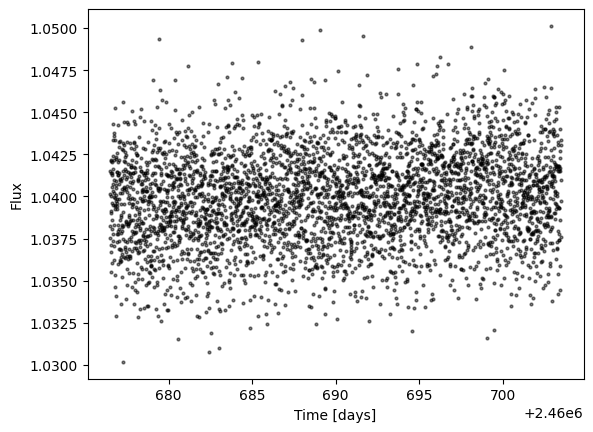

In [11]:
import jax

from src.selflensing.gp import LensingGP as lgp
mag_lc = lgp.build_model_additive(
    gp_theta, 
    5, 
    lgp.make_kernel_fn('GS'), 
    lcg.time_offsets, 
    include_lens_mean=0, 
    noise_measure=tgp.noise_measure,
)
mag_samp = mag_lc.sample(jax.random.PRNGKey(tgp.seed))

plt=pyplot
# Plot the noise-only model
plt.figure()
# plt.errorbar(TESS_times_27/(24 * 60 * 60), noise_samp, yerr=noise_measure, ls = 'none', color = 'grey')
plt.plot(lcg.times.jd, mag_samp, label='Noise-only model', marker ='o', markersize=2, linestyle = 'None', color='black', alpha=0.5)
plt.xlabel('Time [days]')
plt.ylabel('Flux')
plt.show()

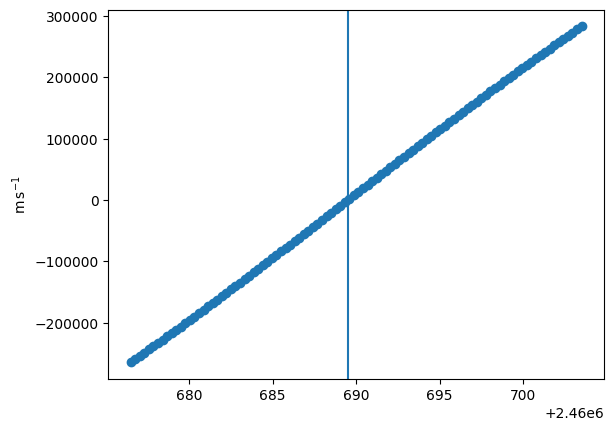

In [12]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.axvline(peak_time.jd)

## Orbital period detection

In [13]:
# import numpy
# peak_mag = numpy.max(lcg.timeseries['flux']) / numpy.median(lcg.timeseries['flux'])
# min_mag = peak_mag * 0.999
# max_mag = peak_mag * 1.001
# min_mag, peak_mag, max_mag

In [14]:
# non_detection_times = [t for t in lcg.time_offsets if t not in lcg.peak_time_offsets]

In [15]:
# from src.selflensing.porb import estimate_porb

# p = estimate_porb(sls.tau_eff, min_mag, max_mag, sls.Rcomp)
# p

In [16]:
# from astropy import units
# bin_starts = units.Quantity(p[0])
# bin_ends = units.Quantity(p[1])
# bin_counts = numpy.array(p[2])
# total_count = sum(bin_counts)

# bin_widths = bin_ends - bin_starts
# bin_centres = (bin_starts + bin_ends) / 2
# n_density = (bin_counts/total_count) / bin_widths.to(units.year).value

# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [17]:
# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.yscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [18]:
# from src.selflensing.porb import LENS_MASS_DIST
# mass_bin_width = LENS_MASS_DIST[0, 1] - LENS_MASS_DIST[0, 0]
# pyplot.plot(LENS_MASS_DIST[0,:], LENS_MASS_DIST[1,:] / mass_bin_width)
# pyplot.axvline(sls.Macc.to(units.M_sun).value)

## Fitting

In [19]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=rvg.rv/10,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    gp_model=tgp,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    tau_eff=sls.tau_eff,
    # period_min=350 * units.day,
    # detect_periods=True,
    nsteps=5000,
    # nwalkers=20,
    burn=10,
    lensing_method=LENSING_METHOD,
)
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time, lensing_method=LENSING_METHOD)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:659: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


ValueError: operands could not be broadcast together with shapes (100,5) (5,11) 

In [ ]:
sls_fit.a, sls_fit.Macc

(<Quantity 193.79684581 AU>, <Quantity 42.69086244 solMass>)

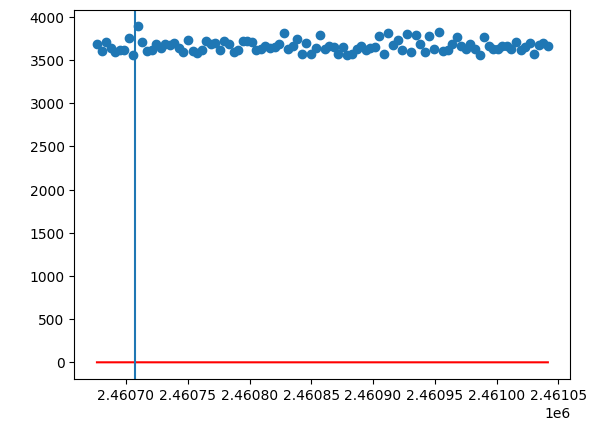

In [ ]:
pyplot.scatter(lcg.times.jd, lcg.flux_array)
pyplot.plot(lcg_fit.times.jd, lcg_fit.flux_array, c='red')
pyplot.axvline(peak_time.jd)

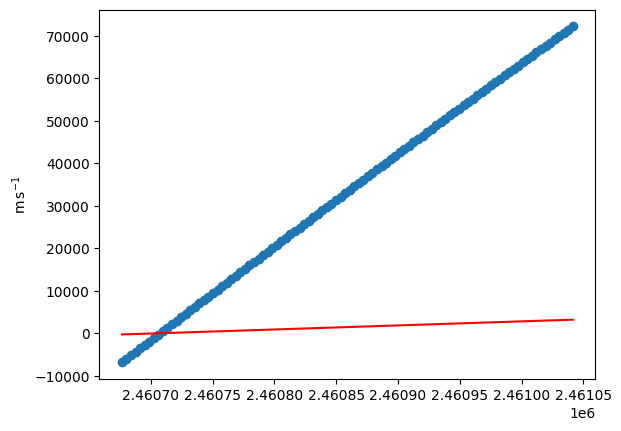

In [ ]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

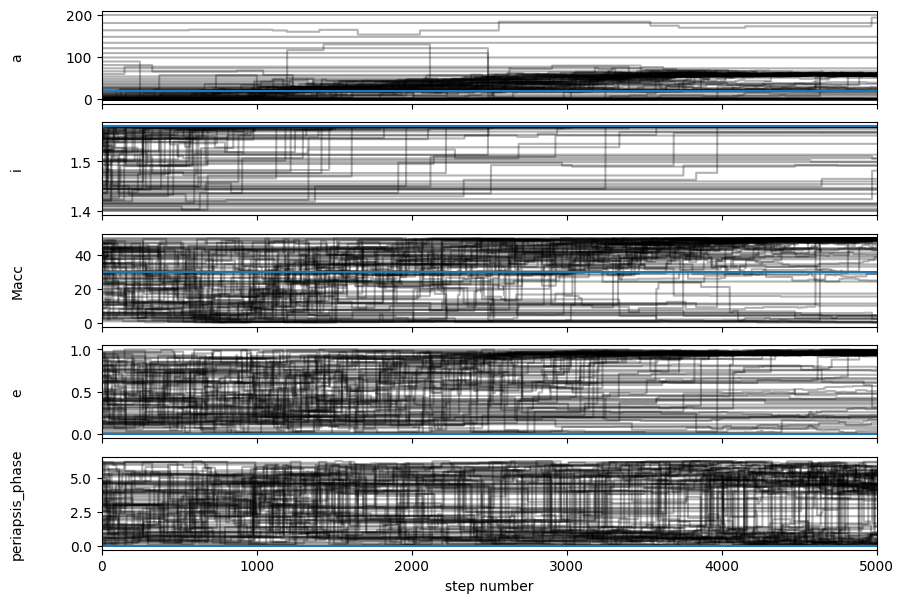

In [ ]:
truths=[sls.a.value, sls.i.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]

from matplotlib import pyplot as plt
labels = ["a", "i", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.axhline(truths[i])
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

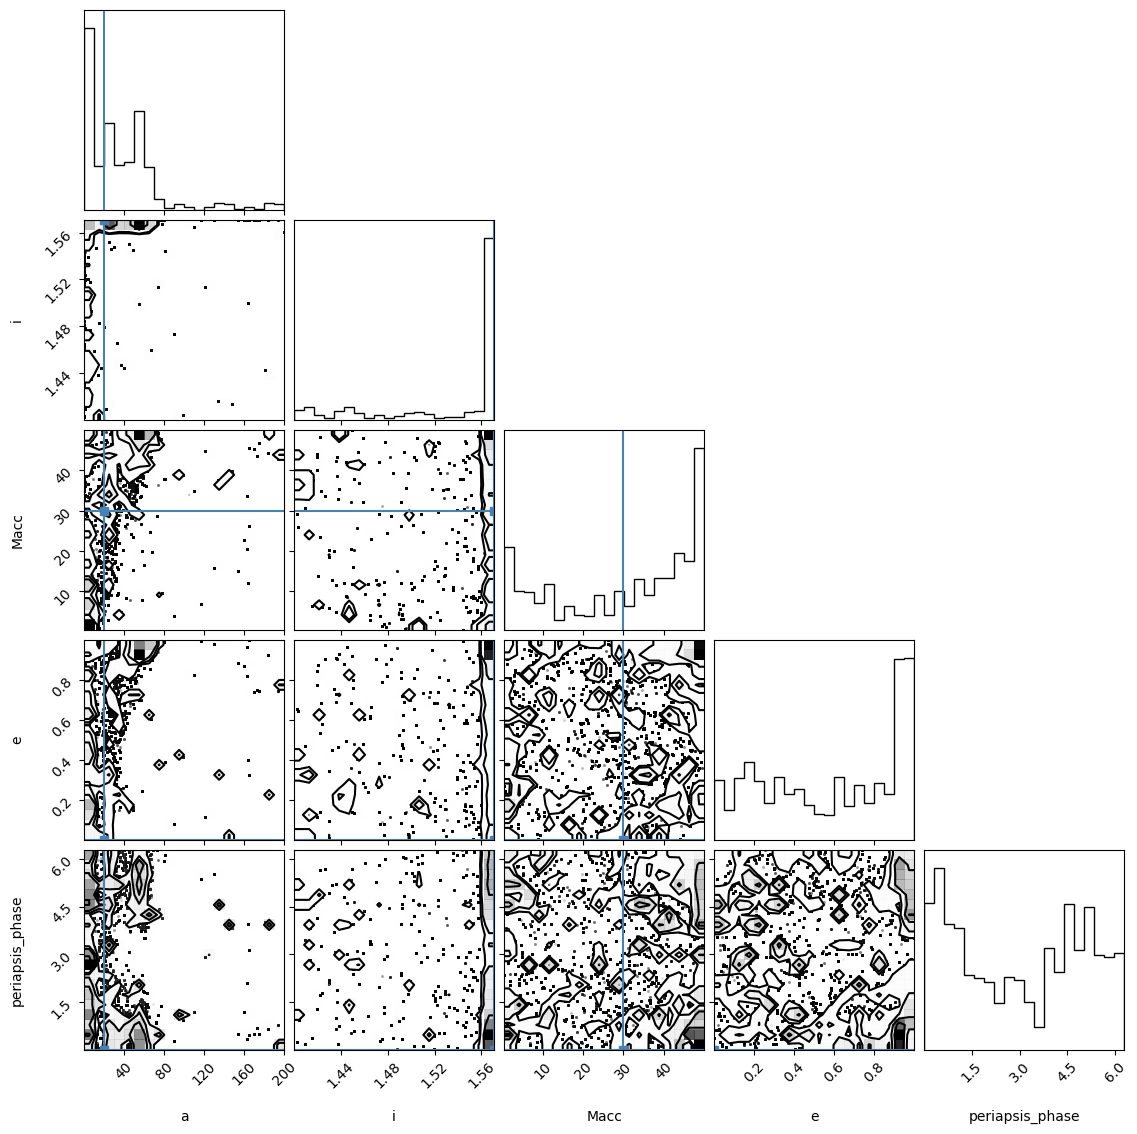

In [ ]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=truths
)